<img src="https://www.institutomillenium.org.br/wp-content/uploads/2024/02/logo-ibmec-topo-rj-450x150.png.webp" width=300>

# 🧰 Caderno de Receitas — Correlação e Regressão Linear com Python

**Para que serve:** reunir, em **funções prontas e simples**, os códigos e gráficos usados nas aulas, para você **copiar e reaproveitar em outros exercícios** trocando apenas o DataFrame e os nomes das colunas.

**Como usar**
1. Rode a célula de **configuração** (Receita 0) e depois as células de **definição das funções** das receitas que quiser usar.
2. Cada receita tem: **quando usar** → **função pronta** → **exemplo** (com dados sintéticos) → **dicas**.
3. Para usar com os seus dados: `df = pd.read_csv('meus_dados.csv')` e chame a função com os seus nomes de colunas.

| # | Receita | Funções principais |
|---|---|---|
| 0 | Configuração e padrão de gráficos | — |
| 1 | Dados sintéticos | `gerar_dados` |
| 2 | Inspeção rápida | `inspecionar` |
| 3 | Gráficos simples | `grafico_histograma`, `grafico_dispersao`, `grafico_linhas` |
| 4 | Correlação e heatmap | `heatmap_correlacao`, `correlacao_com_alvo` |
| 5 | Regressão (simples e múltipla) | `ajustar_regressao`, `mostrar_equacao`, `prever_novo` |
| 6 | Gráficos da regressão | `grafico_reta`, `grafico_real_vs_previsto`, `grafico_residuos`, `grafico_coeficientes` |
| 7 | Métricas e validação cruzada | `avaliar`, `comparar_modelos`, `validacao_cruzada` |
| 8 | Multicolinearidade e variáveis categóricas | `calcular_vif`, `pd.get_dummies` |
| 9 | Séries temporais | `criar_defasagens`, `ajustar_regressao(shuffle=False)` |
| 10 | CAPM (beta e alfa) | `capm`, `grafico_capm` |
| 11 | Modelo para um novo exercício | roteiro em 8 passos |

> Padrão dos gráficos: **simples**, sempre com **título**, **rótulos dos eixos** e **legenda**.

## Receita 0 — Configuração e padrão de gráficos

**Quando usar:** no começo de todo notebook.

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (r2_score, mean_squared_error, mean_absolute_error,
                             mean_absolute_percentage_error)
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

AZUL, OURO, VERM, CINZA = '#16273E', '#F4AC02', '#C0392B', '#8C8C8C'   # cores usadas nas aulas
print('Pronto!')

Pronto!


## Receita 1 — Dados sintéticos

**Quando usar:** para testar uma ideia ou ensinar um conceito **sabendo a resposta certa**. Você define os coeficientes verdadeiros e o ruído; depois confere se a regressão os recupera.

**Como funciona:** `y = intercepto + soma(coef × variável) + ruído normal`.

In [25]:
def gerar_dados(n=100, intervalos=None, coefs=None, intercepto=0.0, ruido=1.0, alvo='y', semente=42):
    """Gera um DataFrame sintético.
    intervalos: {'nome_variavel': (minimo, maximo)}  (variáveis uniformes)
    coefs:      {'nome_variavel': coeficiente_verdadeiro}
    """
    rng = np.random.default_rng(semente)
    df = pd.DataFrame({nome: rng.uniform(lo, hi, n) for nome, (lo, hi) in intervalos.items()})
    df[alvo] = intercepto + sum(coefs[v] * df[v] for v in coefs) + rng.normal(0, ruido, n)
    return df.round(2)

In [26]:
# Exemplo 1: uma variável (horas de estudo -> nota)
df_simples = gerar_dados(n=100, intervalos={'horas_estudo': (0, 10)}, coefs={'horas_estudo': 6},
                         intercepto=30, ruido=6, alvo='nota')

# Exemplo 2: várias variáveis (imóveis)
df_multi = gerar_dados(n=200,
                       intervalos={'area_m2': (40, 200), 'idade_anos': (0, 40), 'dist_centro_km': (1, 20)},
                       coefs={'area_m2': 5, 'idade_anos': -3, 'dist_centro_km': -8},
                       intercepto=150, ruido=60, alvo='preco_mil')
display(df_simples.head(3))
display(df_multi.head(3))

,horas_estudo,nota
0,7.74,78.84
1,4.39,50.90
2,8.59,79.25


,area_m2,idade_anos,dist_centro_km,preco_mil
0,163.83,31.10,6.74,896.86
1,110.22,38.87,18.45,421.73
2,177.38,20.03,15.84,871.84


> 💡 **Dica:** aumente `ruido` para ver o R² cair; troque `semente` para ver que os coeficientes estimados variam um pouco de amostra para amostra.

## Receita 2 — Inspeção rápida dos dados

**Quando usar:** sempre, **antes** de qualquer modelo.

In [27]:
def inspecionar(df):
    """Tamanho, tipos, valores nulos e estatísticas descritivas."""
    print(f'Linhas: {df.shape[0]} | Colunas: {df.shape[1]}')
    print('\nTipos e nulos:')
    display(pd.DataFrame({'tipo': df.dtypes.astype(str), 'nulos': df.isnull().sum()}))
    print('Estatísticas:')
    display(df.describe().round(2))

inspecionar(df_multi)

Linhas: 200 | Colunas: 4

Tipos e nulos:


,tipo,nulos
area_m2,float64,0
idade_anos,float64,0
dist_centro_km,float64,0
preco_mil,float64,0


Estatísticas:


,area_m2,idade_anos,dist_centro_km,preco_mil
count,200.00,200.00,200.00,200.00
mean,119.02,19.97,10.40,598.12
std,45.17,11.54,5.55,244.05
min,41.18,0.49,1.10,46.97
25%,80.35,9.47,5.39,376.99
50%,116.64,20.22,10.59,605.58
75%,159.56,30.66,15.12,806.94
max,198.78,39.47,19.98,1101.22


> 💡 **Dica:** se houver nulos, trate-os antes de ajustar o modelo (`df.dropna()` ou preenchimento); o `LinearRegression` não aceita valores ausentes.

## Receita 3 — Gráficos simples (histograma, dispersão, linhas)

**Quando usar:** para olhar uma variável (histograma), a relação entre duas (dispersão) ou uma série no tempo (linhas).

Todas as funções recebem **título e nomes dos eixos**, e já desenham a **legenda**.

In [28]:
def grafico_histograma(serie, titulo, xlabel, ylabel='Frequência', rotulo=None, bins=15, cor=AZUL):
    plt.figure()
    plt.hist(serie, bins=bins, color=cor, alpha=0.85, label=rotulo or serie.name)
    plt.title(titulo); plt.xlabel(xlabel); plt.ylabel(ylabel); plt.legend()
    plt.show()


def grafico_dispersao(x, y, titulo, xlabel, ylabel, tendencia=True, cor=AZUL):
    """Dispersão com linha de tendência (reta de mínimos quadrados) e r na legenda."""
    plt.figure()
    plt.scatter(x, y, color=cor, alpha=0.7, label='Observações')
    if tendencia:
        coef = np.polyfit(x, y, 1)
        xs = np.linspace(np.min(x), np.max(x), 100)
        r = np.corrcoef(x, y)[0, 1]
        plt.plot(xs, np.polyval(coef, xs), color=VERM, linewidth=2.5, label=f'Tendência (r = {r:.2f})')
    plt.title(titulo); plt.xlabel(xlabel); plt.ylabel(ylabel); plt.legend()
    plt.show()


def grafico_linhas(indice, series, titulo, xlabel, ylabel):
    """series = {'nome na legenda': valores}. Bom para séries no tempo."""
    cores = [AZUL, OURO, VERM, CINZA]
    plt.figure(figsize=(10, 4.5))
    for (nome, valores), cor in zip(series.items(), cores):
        plt.plot(indice, valores, color=cor, linewidth=2, label=nome)
    plt.title(titulo); plt.xlabel(xlabel); plt.ylabel(ylabel); plt.legend()
    plt.show()

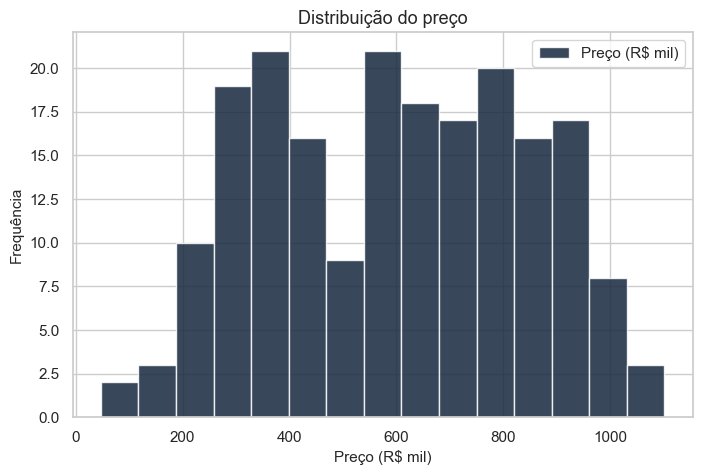

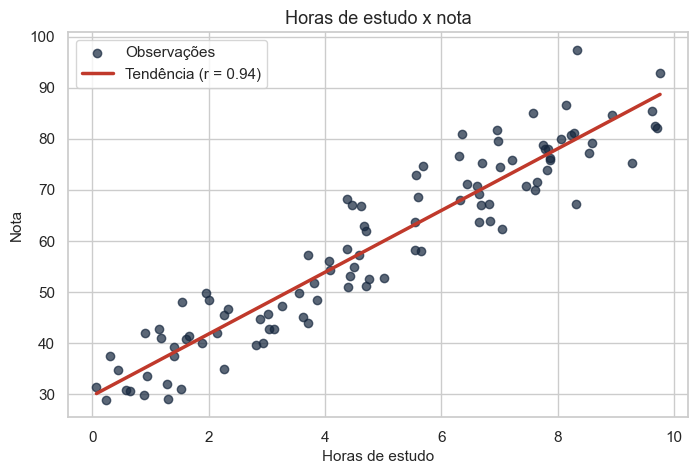

In [29]:
grafico_histograma(df_multi['preco_mil'], 'Distribuição do preço', 'Preço (R$ mil)', rotulo='Preço (R$ mil)')
grafico_dispersao(df_simples['horas_estudo'], df_simples['nota'], 'Horas de estudo x nota', 'Horas de estudo', 'Nota')

## Receita 4 — Correlação e heatmap

**Quando usar:** para descobrir **quais variáveis se relacionam com o alvo** e **quais são redundantes entre si** (multicolinearidade).

- `triangular=True` esconde o triângulo repetido.
- `metodo='spearman'` mede relações monotônicas (menos sensível a outliers).

In [30]:
def heatmap_correlacao(df, titulo='Heatmap de correlação', triangular=False, metodo='pearson', tamanho=(8, 6)):
    corr = df.corr(method=metodo)
    mascara = np.triu(np.ones_like(corr, dtype=bool), k=1) if triangular else None
    plt.figure(figsize=tamanho)
    sns.heatmap(corr, mask=mascara, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
                square=True, linewidths=0.5, cbar_kws={'label': f'Correlação ({metodo})'})
    plt.title(titulo); plt.xlabel('Variáveis'); plt.ylabel('Variáveis'); plt.grid(False)
    plt.show()
    return corr


def correlacao_com_alvo(df, alvo, titulo=None):
    """Barras com a correlação de cada variável com o alvo (ordenadas)."""
    c = df.corr()[alvo].drop(alvo).sort_values()
    plt.figure(figsize=(7, 4))
    plt.barh(c.index, c.values, color=[VERM if v < 0 else AZUL for v in c.values], label=f'Correlação com {alvo}')
    plt.axvline(0, color='black', linewidth=1)
    plt.title(titulo or f'Correlação com {alvo}'); plt.xlabel('Correlação de Pearson (r)'); plt.ylabel('Variável')
    plt.legend(loc='lower right')
    plt.show()
    return c

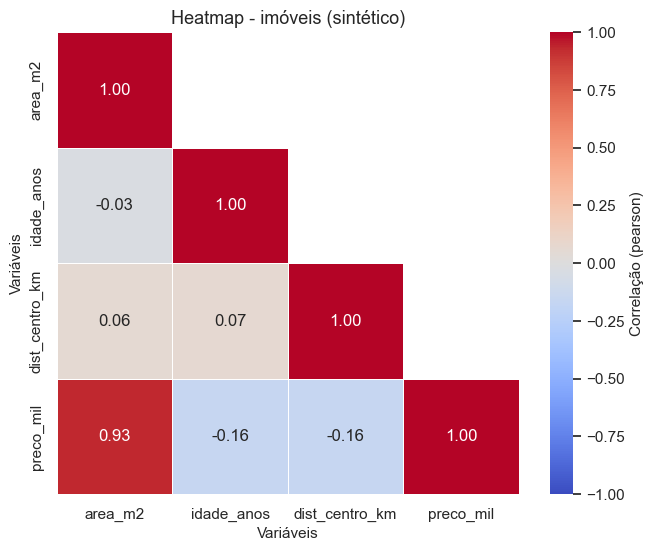

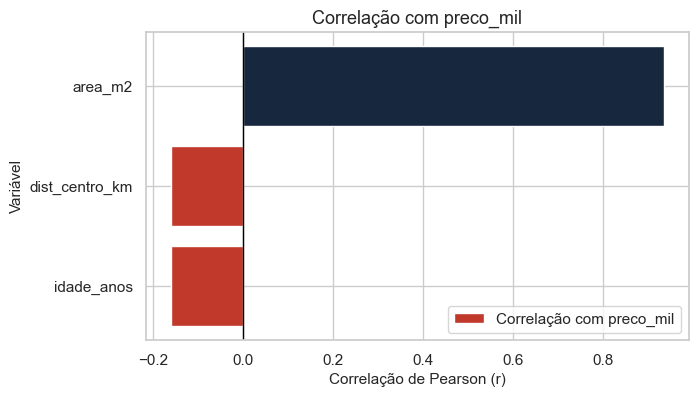

In [31]:
corr = heatmap_correlacao(df_multi, 'Heatmap - imóveis (sintético)', triangular=True)
_ = correlacao_com_alvo(df_multi, 'preco_mil')

> ⚠️ **Lembre:** correlação **não** é causalidade; r só mede relação **linear**; olhe sempre o gráfico de dispersão.

## Receita 5 — Regressão linear (simples ou múltipla) em uma função

**Quando usar:** sempre que quiser ajustar uma regressão linear. **Uma variável em `features` = regressão simples; várias = múltipla.**

A função faz as etapas das aulas: `X` e `y` → treino/teste → `fit` → `predict`, e devolve tudo em um dicionário (`res`) que as outras receitas reaproveitam.

In [32]:
def ajustar_regressao(df, features, alvo, test_size=0.2, semente=42, shuffle=True):
    """Ajusta LinearRegression. features: lista de colunas. shuffle=False para séries temporais."""
    X, y = df[features], df[alvo]
    kw = {'random_state': semente} if shuffle else {}
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=test_size, shuffle=shuffle, **kw)
    modelo = LinearRegression().fit(X_tr, y_tr)
    return {'modelo': modelo, 'features': features, 'alvo': alvo,
            'X_treino': X_tr, 'X_teste': X_te, 'y_treino': y_tr, 'y_teste': y_te,
            'y_prev': modelo.predict(X_te)}


def mostrar_equacao(res, casas=2):
    m = res['modelo']
    termos = ' '.join(f'{b:+.{casas}f}·{f}' for b, f in zip(m.coef_, res['features']))
    print(f"{res['alvo']} = {m.intercept_:.{casas}f} {termos}")
    print(f"R² treino: {m.score(res['X_treino'], res['y_treino']):.3f} | R² teste: {r2_score(res['y_teste'], res['y_prev']):.3f}")
    for b, f in zip(m.coef_, res['features']):
        print(f"  +1 em {f}: {b:+.{casas}f} em {res['alvo']} (mantendo as demais constantes)")


def prever_novo(res, **valores):
    """prever_novo(res, horas_estudo=7.5)  -> previsão para um caso novo."""
    novo = pd.DataFrame({f: [valores[f]] for f in res['features']})
    return res['modelo'].predict(novo)[0]

In [33]:
# Regressão SIMPLES
res_s = ajustar_regressao(df_simples, ['horas_estudo'], 'nota')
mostrar_equacao(res_s)
print('Nota prevista para 7,5 h:', round(prever_novo(res_s, horas_estudo=7.5), 1))

# Regressão MÚLTIPLA
res_m = ajustar_regressao(df_multi, ['area_m2', 'idade_anos', 'dist_centro_km'], 'preco_mil')
print()
mostrar_equacao(res_m)

nota = 29.69 +6.15·horas_estudo
R² treino: 0.883 | R² teste: 0.896
  +1 em horas_estudo: +6.15 em nota (mantendo as demais constantes)
Nota prevista para 7,5 h: 75.8

preco_mil = 139.37 +5.05·area_m2 -2.43·idade_anos -9.16·dist_centro_km
R² treino: 0.934 | R² teste: 0.929
  +1 em area_m2: +5.05 em preco_mil (mantendo as demais constantes)
  +1 em idade_anos: -2.43 em preco_mil (mantendo as demais constantes)
  +1 em dist_centro_km: -9.16 em preco_mil (mantendo as demais constantes)


## Receita 6 — Gráficos da regressão

**Quando usar:** depois de ajustar (`res = ajustar_regressao(...)`), para **ver** o ajuste e **diagnosticar**.

| Gráfico | O que mostra | O que procurar |
|---|---|---|
| `grafico_reta` | dados de treino/teste e a reta (só regressão simples) | reta passando "pelo meio" dos pontos |
| `grafico_real_vs_previsto` | real × previsto, com a diagonal de 45° | pontos colados na diagonal |
| `grafico_residuos` | histograma e resíduos × previstos | nuvem sem padrão em torno de zero |
| `grafico_coeficientes` | efeito de cada variável (padronizado ou bruto) | sinais e tamanhos relativos |

In [34]:
def grafico_reta(res, titulo=None, xlabel=None, ylabel=None):
    """Regressão simples: treino, teste e reta ajustada."""
    f = res['features'][0]
    m = res['modelo']
    xs = pd.DataFrame({f: np.linspace(res['X_treino'][f].min(), res['X_treino'][f].max(), 100)})
    plt.figure()
    plt.scatter(res['X_treino'][f], res['y_treino'], color=AZUL, alpha=0.7, label='Treino')
    plt.scatter(res['X_teste'][f], res['y_teste'], color=OURO, edgecolor='black', s=70, label='Teste')
    plt.plot(xs[f], m.predict(xs), color=VERM, linewidth=2.5, label=f'Reta: {m.intercept_:.1f} + {m.coef_[0]:.2f}x')
    plt.title(titulo or f'{res["alvo"]} x {f}'); plt.xlabel(xlabel or f); plt.ylabel(ylabel or res['alvo']); plt.legend()
    plt.show()


def grafico_real_vs_previsto(res, titulo='Real x previsto (teste)'):
    y, p = res['y_teste'], res['y_prev']
    lim = [min(y.min(), p.min()), max(y.max(), p.max())]
    plt.figure(figsize=(6.5, 6))
    plt.scatter(y, p, color=AZUL, alpha=0.7, label='Observações (teste)')
    plt.plot(lim, lim, color=VERM, linestyle='--', linewidth=2, label='Previsão perfeita (45°)')
    plt.title(titulo); plt.xlabel(f'{res["alvo"]} real'); plt.ylabel(f'{res["alvo"]} previsto'); plt.legend()
    plt.show()


def grafico_residuos(res):
    r = res['y_teste'] - res['y_prev']
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
    ax[0].hist(r, bins=15, color=AZUL, alpha=0.85, label='Resíduos')
    ax[0].axvline(0, color=VERM, linestyle='--', linewidth=2, label='Zero')
    ax[0].set_title('Distribuição dos resíduos'); ax[0].set_xlabel('Resíduo'); ax[0].set_ylabel('Frequência'); ax[0].legend()
    ax[1].scatter(res['y_prev'], r, color=AZUL, alpha=0.7, label='Resíduo')
    ax[1].axhline(0, color=VERM, linestyle='--', linewidth=2, label='Resíduo = 0')
    ax[1].set_title('Resíduos x previstos'); ax[1].set_xlabel('Valor previsto'); ax[1].set_ylabel('Resíduo'); ax[1].legend()
    plt.tight_layout()
    plt.show()


def grafico_coeficientes(res, padronizar=True):
    """Coeficientes em barras. padronizar=True permite comparar variáveis em unidades diferentes."""
    X = res['X_treino']
    if padronizar:
        sc = StandardScaler().fit(X)
        coef = pd.Series(LinearRegression().fit(sc.transform(X), res['y_treino']).coef_, index=res['features'])
        xl = 'Coeficiente padronizado (por desvio-padrão)'
    else:
        coef = pd.Series(res['modelo'].coef_, index=res['features'])
        xl = 'Coeficiente (por unidade)'
    pos, neg = coef[coef >= 0], coef[coef < 0]
    plt.figure(figsize=(8, 4))
    plt.barh(pos.index, pos.values, color=AZUL, label='Efeito positivo')
    plt.barh(neg.index, neg.values, color=VERM, label='Efeito negativo')
    plt.axvline(0, color='black', linewidth=1)
    plt.title('Efeito de cada variável'); plt.xlabel(xl); plt.ylabel('Variável'); plt.legend()
    plt.show()

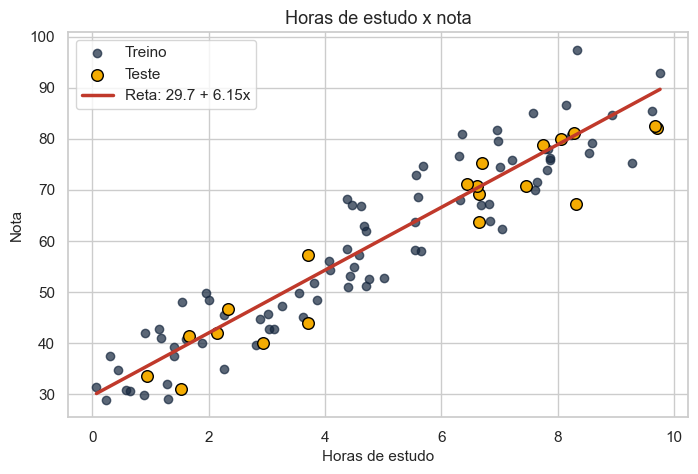

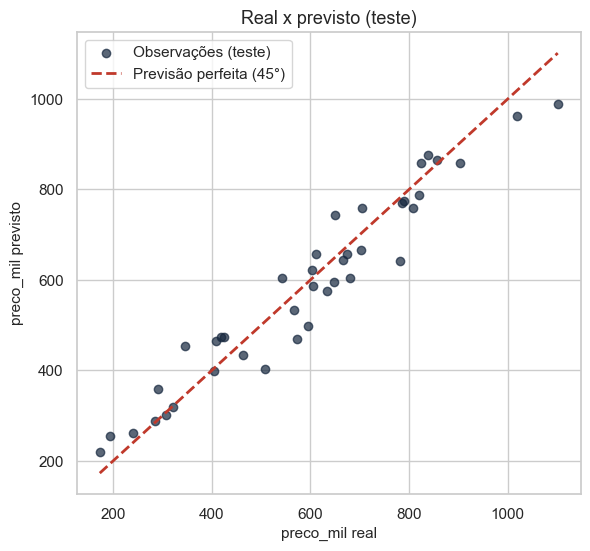

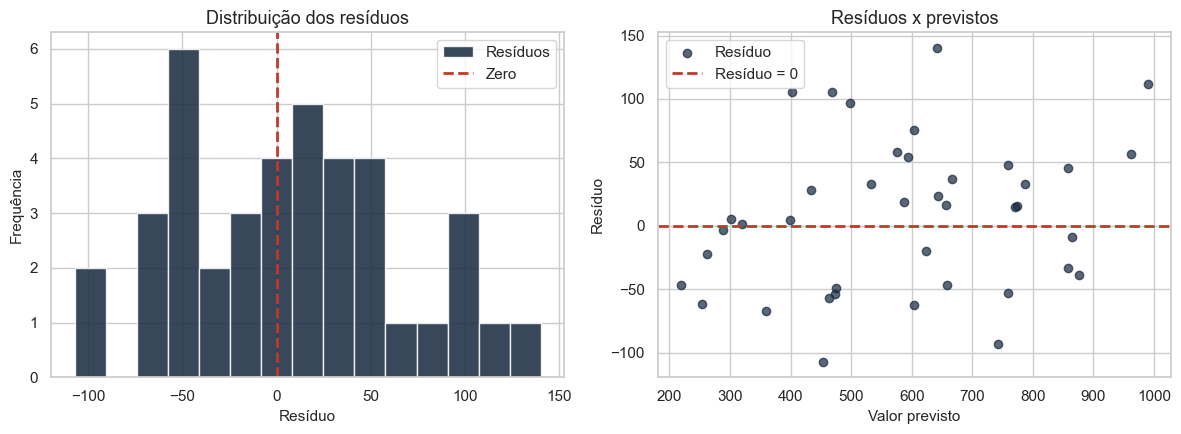

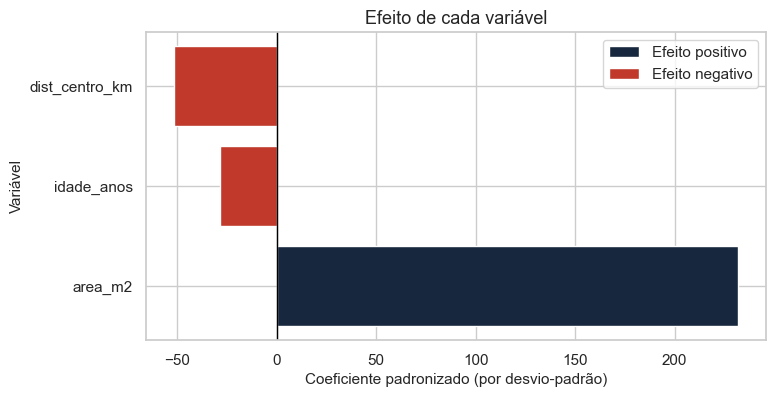

In [35]:
grafico_reta(res_s, 'Horas de estudo x nota', 'Horas de estudo', 'Nota')
grafico_real_vs_previsto(res_m)
grafico_residuos(res_m)
grafico_coeficientes(res_m)

## Receita 7 — Métricas e validação cruzada

**Quando usar:** para dizer **quão bom** é o modelo (sempre no **teste**) e para **comparar** modelos.

| Métrica | Lê-se como | Quando preferir |
|---|---|---|
| **RMSE** | erro típico, na unidade do alvo | erros grandes são especialmente ruins |
| **MAE** | erro absoluto médio | há outliers / todos os erros pesam igual |
| **MAPE (%)** | erro percentual médio | comunicar a não técnicos (evite se y ≈ 0) |
| **R²** | proporção da variância explicada | comparar modelos para o mesmo alvo |
| **R² ajustado** | R² penalizado por nº de variáveis | comparar modelos com nº diferente de variáveis |

In [36]:
def avaliar(y_real, y_prev, p):
    """Todas as métricas de regressão. p = número de variáveis explicativas."""
    n = len(y_real)
    mse = mean_squared_error(y_real, y_prev)
    r2 = r2_score(y_real, y_prev)
    return {'MSE': mse, 'RMSE': np.sqrt(mse), 'MAE': mean_absolute_error(y_real, y_prev),
            'MAPE (%)': 100 * mean_absolute_percentage_error(y_real, y_prev),
            'R²': r2, 'R² ajustado': 1 - (1 - r2) * (n - 1) / (n - p - 1)}


def comparar_modelos(resultados):
    """resultados = {'nome do modelo': res}. Devolve tabela de métricas no TESTE e desenha RMSE/MAE."""
    tabela = pd.DataFrame({nome: avaliar(r['y_teste'], r['y_prev'], len(r['features']))
                           for nome, r in resultados.items()}).round(3)
    erros = tabela.loc[['RMSE', 'MAE']]
    pos = np.arange(len(erros.index)); larg = 0.8 / len(erros.columns)
    plt.figure(figsize=(7.5, 4.5))
    for i, (nome, cor) in enumerate(zip(erros.columns, [AZUL, OURO, VERM, CINZA])):
        plt.bar(pos + i * larg - 0.4 + larg / 2, erros[nome], width=larg, color=cor, label=nome)
    plt.xticks(pos, erros.index)
    plt.title('Erro no teste'); plt.xlabel('Métrica'); plt.ylabel('Erro (unidade do alvo)'); plt.legend()
    plt.show()
    return tabela


def validacao_cruzada(df, features, alvo, k=5):
    """R² em k partes (média e dispersão mostram a estabilidade do modelo)."""
    r2s = cross_val_score(LinearRegression(), df[features], df[alvo], cv=k, scoring='r2')
    plt.figure(figsize=(7, 4.5))
    plt.bar([f'Parte {i+1}' for i in range(k)], r2s, color=AZUL, label='R² por parte')
    plt.axhline(r2s.mean(), color=VERM, linestyle='--', linewidth=2, label=f'Média = {r2s.mean():.3f}')
    plt.title(f'Validação cruzada ({k} partes)'); plt.xlabel('Parte usada como teste'); plt.ylabel('R²')
    plt.ylim(min(0, r2s.min()) - 0.05, 1.12); plt.legend(loc='upper center', ncol=2)
    plt.show()
    return r2s

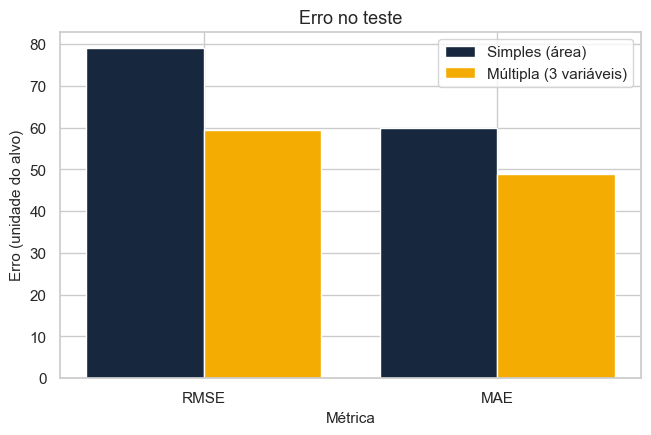

,Simples (área),Múltipla (3 variáveis)
MSE,6247.454,3536.064
RMSE,79.041,59.465
MAE,60.024,48.896
MAPE (%),12.742,9.563
R²,0.875,0.929
R² ajustado,0.872,0.923


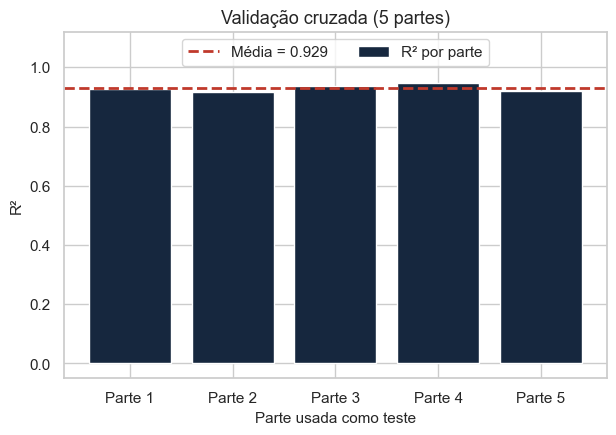

In [37]:
res_s2 = ajustar_regressao(df_multi, ['area_m2'], 'preco_mil')          # só a área
tabela = comparar_modelos({'Simples (área)': res_s2, 'Múltipla (3 variáveis)': res_m})
display(tabela)
r2s = validacao_cruzada(df_multi, ['area_m2', 'idade_anos', 'dist_centro_km'], 'preco_mil')

## Receita 8 — Multicolinearidade (VIF) e variáveis categóricas (dummies)

**VIF — quando usar:** quando duas ou mais variáveis explicativas são muito correlacionadas. **VIF < 5** tranquilo · **5–10** atenção · **> 10** problema (coeficientes instáveis).

**Dummies — quando usar:** quando uma variável é **categórica** (bairro, setor, sexo). `drop_first=True` descarta uma categoria, que vira a **referência**.

In [38]:
def calcular_vif(df_x):
    """VIF de cada coluna: regride a coluna nas demais e calcula 1 / (1 - R²)."""
    vifs = {}
    for col in df_x.columns:
        outras = df_x.drop(columns=col)
        r2 = LinearRegression().fit(outras, df_x[col]).score(outras, df_x[col])
        vifs[col] = 1 / (1 - r2)
    return pd.Series(vifs, name='VIF').round(2)

In [39]:
# Variável redundante de propósito: a mesma área em pés quadrados (com pequeno ruído)
rng = np.random.default_rng(3)
df_red = df_multi[['area_m2', 'idade_anos', 'dist_centro_km']].copy()
print('VIF sem redundância:'); display(calcular_vif(df_red).to_frame())
df_red['area_pes2'] = df_red['area_m2'] * 10.764 + rng.normal(0, 5, len(df_red))
print('VIF COM redundância (area_m2 e area_pes2 explodem):'); display(calcular_vif(df_red).to_frame())

# Dummies: transformar uma coluna de texto em colunas 0/1
df_cat = df_multi.copy()
df_cat['bairro'] = np.random.default_rng(11).choice(['Centro', 'Zona Norte', 'Zona Sul'], size=len(df_cat))
X_cat = pd.get_dummies(df_cat[['area_m2', 'bairro']], columns=['bairro'], drop_first=True, dtype=int)
display(X_cat.head(3))
print('Categoria de referência: Centro (a que foi descartada).')

VIF sem redundância:


,VIF
area_m2,1.00
idade_anos,1.01
dist_centro_km,1.01


VIF COM redundância (area_m2 e area_pes2 explodem):


,VIF
area_m2,8868.11
idade_anos,1.01
dist_centro_km,1.01
area_pes2,8867.99


,area_m2,bairro_Zona Norte,bairro_Zona Sul
0,163.83,0,0
1,110.22,0,0
2,177.38,0,1


Categoria de referência: Centro (a que foi descartada).


## Receita 9 — Séries temporais: defasagens, divisão temporal e baseline

**Quando usar:** quando as linhas são **meses/dias** e você quer **prever o futuro**.

1. **Defasagens** (`shift`): use o valor **anterior** como explicativa (só informação disponível antes da previsão).
2. **Divisão temporal**: treino = passado, teste = futuro (`shuffle=False`). **Nunca embaralhe.**
3. **Baseline ingênuo**: "valor de hoje = valor de ontem". O modelo só vale a pena se **superar** o baseline.

In [40]:
def criar_defasagens(df, colunas, n=1):
    """Acrescenta colunas <col>_lag<k> (k = 1..n) e remove as primeiras linhas sem defasagem."""
    out = df.copy()
    for col in colunas:
        for k in range(1, n + 1):
            out[f'{col}_lag{k}'] = df[col].shift(k)
    return out.dropna()

,Regressão,Baseline (valor anterior)
RMSE,0.306,1.084
MAE,0.246,0.818
R²,0.891,-0.365


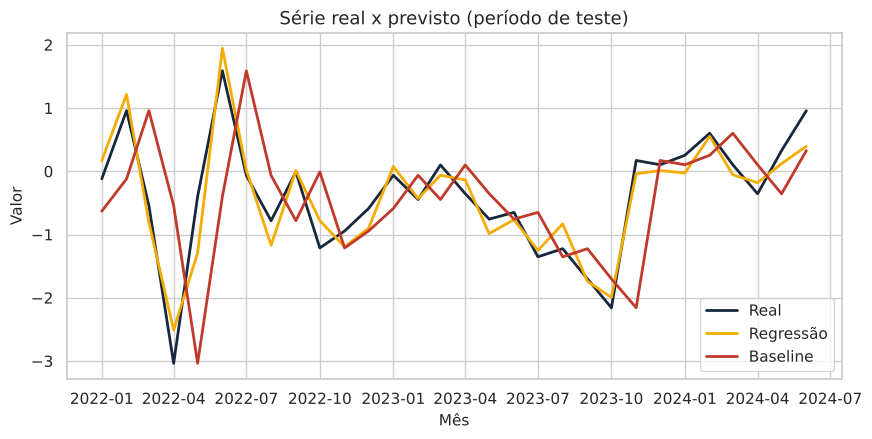

In [18]:
# Série sintética com inércia: valor de hoje depende do de ontem e de uma variável externa x
rs = np.random.default_rng(1)
T = 150
x = rs.normal(0, 1, T)
y = np.zeros(T)
for t in range(1, T):
    y[t] = 0.6 * y[t-1] + 0.8 * x[t-1] + rs.normal(0, 0.3)
serie = pd.DataFrame({'y': y, 'x': x}, index=pd.period_range('2012-01', periods=T, freq='M'))

dados_ts = criar_defasagens(serie, ['y', 'x'], n=1)
feats = ['y_lag1', 'x_lag1']
res_ts = ajustar_regressao(dados_ts, feats, 'y', shuffle=False)       # divisão temporal

baseline = res_ts['X_teste']['y_lag1']                                # previsão ingênua
tab = pd.DataFrame({'Regressão': avaliar(res_ts['y_teste'], res_ts['y_prev'], 2),
                    'Baseline (valor anterior)': avaliar(res_ts['y_teste'], baseline, 0)}).round(3)
display(tab.loc[['RMSE', 'MAE', 'R²']])

datas = res_ts['y_teste'].index.to_timestamp()
grafico_linhas(datas, {'Real': res_ts['y_teste'].values, 'Regressão': res_ts['y_prev'], 'Baseline': baseline.values},
               'Série real x previsto (período de teste)', 'Mês', 'Valor')

## Receita 10 — CAPM: beta e alfa de uma ação

### Em palavras simples
- O **mercado** (ex.: Ibovespa) é a **maré**; a **ação** é o **barco**.
- **Beta (β)**: quanto o barco sobe/desce quando a maré sobe/desce. **β = 1** acompanha · **β > 1** exagera (agressiva) · **β < 1** amortece (defensiva).
- **Alfa (α)**: bônus (ou penalidade) que a maré **não** explica. α > 0 foi melhor que o risco justificaria.
- **R²**: parte do movimento da ação **explicada pelo mercado**; o resto é risco específico da empresa.
- **Retorno em excesso** = retorno − **CDI** (o CDI é o "dinheiro seguro" brasileiro: taxa média dos empréstimos de um dia entre bancos, colada na Selic).

### Em código
É uma **regressão linear simples**: `excesso da ação ~ excesso do mercado`. **Beta = coeficiente angular; alfa = intercepto.**

**Quando usar:** para medir o risco de mercado de qualquer ativo contra um índice de referência.

In [19]:
def capm(retorno_ativo, retorno_mercado, taxa_livre, nome='Ativo'):
    """CAPM por regressão simples. Entradas: Series de retornos (fração, ex.: 0.02 = 2%) com o mesmo índice.
    Devolve (modelo, resumo)."""
    exc_a = retorno_ativo - taxa_livre            # excesso do ativo
    exc_m = retorno_mercado - taxa_livre          # excesso do mercado
    modelo = LinearRegression().fit(exc_m.to_frame('mercado'), exc_a)
    resumo = {'ativo': nome, 'beta': modelo.coef_[0], 'alfa_mensal_%': 100 * modelo.intercept_,
              'R2': modelo.score(exc_m.to_frame('mercado'), exc_a), 'n_obs': len(exc_a)}
    return modelo, resumo, exc_m, exc_a


def grafico_capm(exc_m, exc_a, modelo, nome='Ativo'):
    xs = np.linspace(exc_m.min(), exc_m.max(), 50)
    plt.figure(figsize=(7.5, 5))
    plt.scatter(exc_m * 100, exc_a * 100, color=AZUL, alpha=0.8, label=f'{nome} (meses)')
    plt.plot(xs * 100, modelo.predict(pd.DataFrame({'mercado': xs})) * 100, color=VERM, linewidth=2.5,
             label=f'Reta CAPM: beta = {modelo.coef_[0]:.2f}')
    plt.plot(xs * 100, xs * 100, color=CINZA, linestyle='--', label='Beta = 1')
    plt.title(f'CAPM de {nome}'); plt.xlabel('Excesso do mercado sobre o CDI (% a.m.)'); plt.ylabel(f'Excesso de {nome} sobre o CDI (% a.m.)')
    plt.legend()
    plt.show()

,beta,alfa_mensal_%,R2,n_obs
ativo,,,,
ACAO_X,1.289,0.385,0.722,72


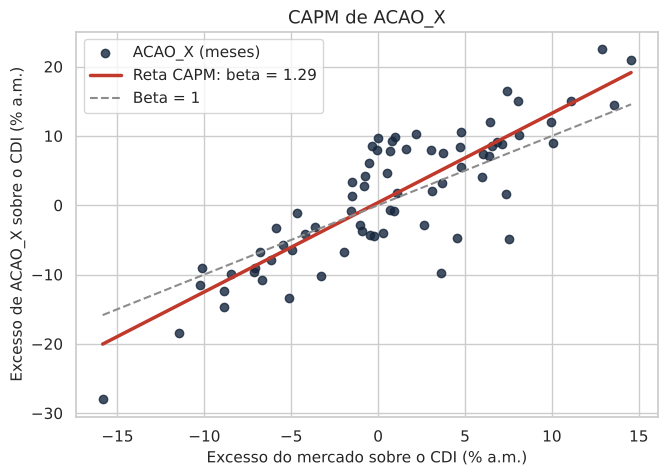

In [20]:
# Exemplo com retornos mensais SIMULADOS (ação agressiva, beta verdadeiro = 1,3)
rs = np.random.default_rng(4)
meses = pd.period_range('2020-01', periods=72, freq='M')
cdi = pd.Series(0.0085 + rs.normal(0, 0.0015, 72), index=meses)
mercado = cdi + pd.Series(rs.normal(0, 0.06, 72), index=meses)
acao = cdi + 0.002 + 1.3 * (mercado - cdi) + pd.Series(rs.normal(0, 0.05, 72), index=meses)

modelo, resumo, exc_m, exc_a = capm(acao, mercado, cdi, nome='ACAO_X')
display(pd.DataFrame([resumo]).set_index('ativo').round(3))
grafico_capm(exc_m, exc_a, modelo, 'ACAO_X')

### Com dados reais (precisa de internet)

```python
import yfinance as yf
precos = yf.download(['PETR4.SA', '^BVSP'], start='2019-12-01', end='2026-01-01',
                     interval='1mo', auto_adjust=True, progress=False)['Close']
ret = precos.pct_change().dropna()
ret.index = ret.index.to_period('M')

# CDI mensal (série 4391 do Banco Central), em % -> fração
import requests
url = ('https://api.bcb.gov.br/dados/serie/bcdata.sgs.4391/dados?formato=json'
       '&dataInicial=01/01/2020&dataFinal=31/12/2025')
bruto = pd.DataFrame(requests.get(url, timeout=20).json())
datas = pd.DatetimeIndex(pd.to_datetime(bruto['data'], dayfirst=True))      # índice de datas (não Series)
cdi = pd.Series(bruto['valor'].astype(float).values / 100, index=datas.to_period('M'))   # % -> fração

modelo, resumo, exc_m, exc_a = capm(ret['PETR4.SA'], ret['^BVSP'], cdi, 'PETR4')
```

> ⚠️ O alfa vem **sem p-valor** (só scikit-learn): trate-o com cautela. O beta **muda no tempo**: compare períodos diferentes.

## Receita 11 — Modelo para um novo exercício (8 passos)

Copie a célula abaixo, troque o DataFrame e os nomes das colunas.

| Passo | Pergunta | Receita |
|---|---|---|
| 1 | Os dados estão carregados e limpos? | 2 |
| 2 | Como são as variáveis? | 3 |
| 3 | Quais se relacionam com o alvo? Há redundância? | 4 e 8 |
| 4 | Ajuste (treino/teste) | 5 |
| 5 | Os coeficientes fazem sentido? | 5 e 6 |
| 6 | Quão bom é o modelo no teste? | 7 |
| 7 | Os resíduos têm padrão? | 6 |
| 8 | O que concluir (e quais as limitações)? | — |

Linhas: 200 | Colunas: 4

Tipos e nulos:


,tipo,nulos
area_m2,float64,0
idade_anos,float64,0
dist_centro_km,float64,0
preco_mil,float64,0


Estatísticas:


,area_m2,idade_anos,dist_centro_km,preco_mil
count,200.00,200.00,200.00,200.00
mean,119.02,19.97,10.40,598.12
std,45.17,11.54,5.55,244.05
min,41.18,0.49,1.10,46.97
25%,80.35,9.47,5.39,376.99
50%,116.64,20.22,10.59,605.58
75%,159.56,30.66,15.12,806.94
max,198.78,39.47,19.98,1101.22


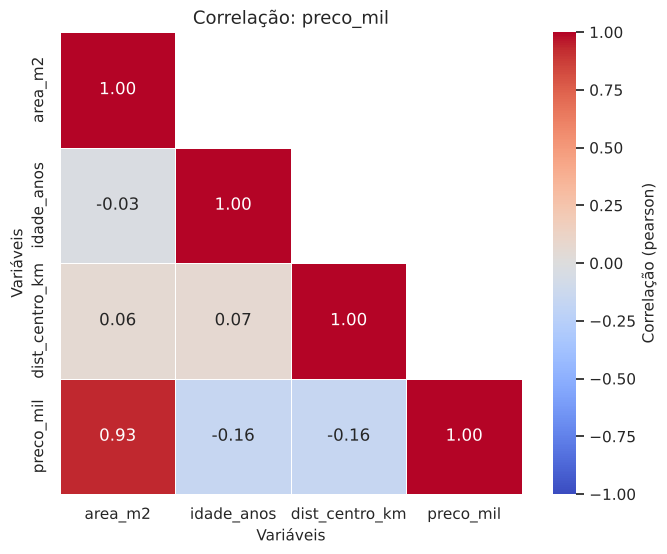

     area_m2  idade_anos  dist_centro_km
VIF      1.0        1.01            1.01
preco_mil = 139.37 +5.05·area_m2 -2.43·idade_anos -9.16·dist_centro_km
R² treino: 0.934 | R² teste: 0.929
  +1 em area_m2: +5.05 em preco_mil (mantendo as demais constantes)
  +1 em idade_anos: -2.43 em preco_mil (mantendo as demais constantes)
  +1 em dist_centro_km: -9.16 em preco_mil (mantendo as demais constantes)


,Modelo
MSE,3536.064
RMSE,59.465
MAE,48.896
MAPE (%),9.563
R²,0.929
R² ajustado,0.923


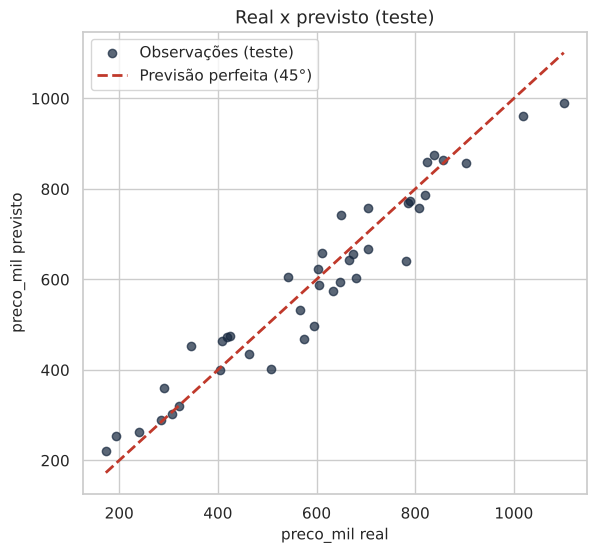

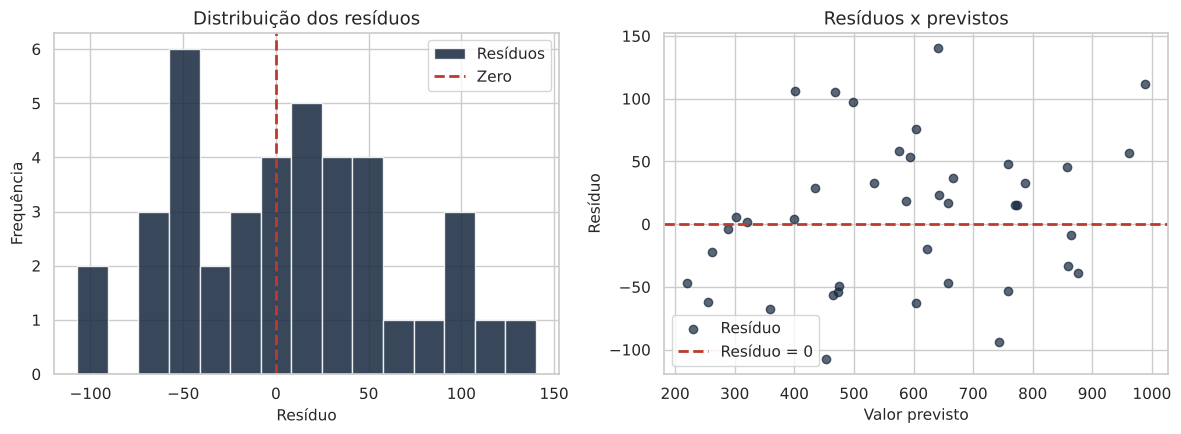

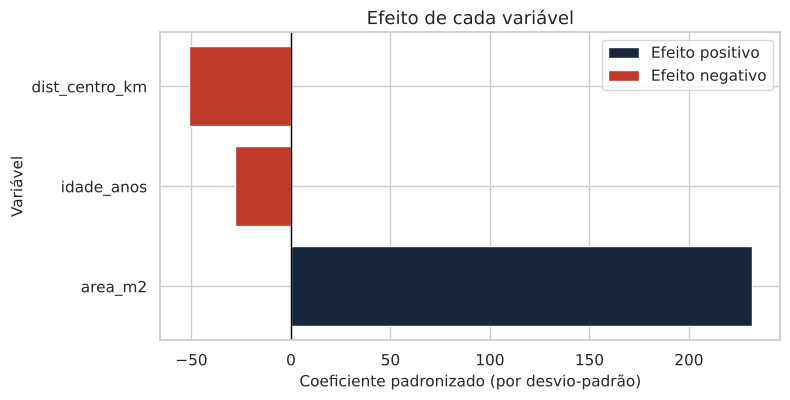

In [21]:
# ===== MODELO PARA UM NOVO EXERCÍCIO: troque só estas 3 linhas =====
df = df_multi                                        # seu DataFrame (ex.: pd.read_csv('arquivo.csv'))
alvo = 'preco_mil'                                   # coluna que você quer prever
features = ['area_m2', 'idade_anos', 'dist_centro_km']   # colunas explicativas (1 = simples, várias = múltipla)
# ====================================================================

inspecionar(df[features + [alvo]])
heatmap_correlacao(df[features + [alvo]], f'Correlação: {alvo}', triangular=True)
print(calcular_vif(df[features]).to_frame().T) if len(features) > 1 else None

res = ajustar_regressao(df, features, alvo)
mostrar_equacao(res)
display(pd.DataFrame({'Modelo': avaliar(res['y_teste'], res['y_prev'], len(features))}).round(3))

grafico_real_vs_previsto(res)
grafico_residuos(res)
grafico_coeficientes(res)

## ✅ Checklist final

- [ ] Olhei os dados e os gráficos antes de modelar?
- [ ] Separei treino e teste (e, em séries temporais, **sem embaralhar**)?
- [ ] Interpretei os coeficientes **mantendo as demais variáveis constantes**?
- [ ] Reportei as métricas **no teste** (RMSE/MAE na unidade do alvo, R²)?
- [ ] Comparei com um **baseline** (ou com um modelo mais simples)?
- [ ] Verifiquei os **resíduos** e a **multicolinearidade** (VIF)?
- [ ] Lembrei que **correlação não é causalidade** e citei as limitações?